In [5]:
import sys

print("Python executable:", sys.executable)
print("Python version:", sys.version)

Python executable: d:\BITS MTECH\ML Assigment\aiml_assignment2\venv\Scripts\python.exe
Python version: 3.10.11 (tags/v3.10.11:7d4cc5a, Apr  5 2023, 00:38:17) [MSC v.1929 64 bit (AMD64)]


# Machine Learning Assignment 2
## Classification Models and Performance Evaluation

**Dataset:** Breast Cancer Wisconsin Diagnostic Dataset

**Objective:** To implement and compare five machine learning
classification algorithms using different evaluation metrics.

In [6]:
# Importing the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

# Dataset download utilities
from pathlib import Path
from urllib.request import urlretrieve

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("All libraries imported successfully!")

All libraries imported successfully!


## 1. Dataset Collection and Loading

The Breast Cancer Wisconsin Diagnostic dataset is obtained
from the UCI Machine Learning Repository.

In [7]:
from pathlib import Path
from urllib.request import urlretrieve

data_folder = Path("data")
data_folder.mkdir(exist_ok=True)

dataset_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data"

dataset_path = data_folder / "wdbc.data"

if not dataset_path.exists():
    urlretrieve(dataset_url, dataset_path)
    print("Dataset downloaded successfully!")
else:
    print("Dataset already exists.")

print("Dataset path:", dataset_path)

Dataset downloaded successfully!
Dataset path: data\wdbc.data


In [8]:
base_features = [
    "radius", "texture", "perimeter", "area", "smoothness",
    "compactness", "concavity", "concave_points", "symmetry",
    "fractal_dimension"
]

feature_names = [
    f"{feature}_{suffix}"
    for suffix in ["mean", "se", "worst"]
    for feature in base_features
]

column_names = ["id", "diagnosis"] + feature_names

df = pd.read_csv(
    dataset_path,
    header=None,
    names=column_names
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (569, 32)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 2. Exploratory Data Analysis

The dataset is examined to understand its structure,
feature distributions, missing values and target classes.

In [9]:
print("Dataset dimensions:", df.shape)

print("\nColumn information:")
df.info()

Dataset dimensions: (569, 32)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave_points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 

In [10]:
df.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,0.405172,1.216853,2.866059,40.337079,0.007041,0.025478,0.031894,0.011796,0.020542,0.003795,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,0.277313,0.551648,2.021855,45.491006,0.003003,0.017908,0.030186,0.006170,0.008266,0.002646,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,0.111500,0.360200,0.757000,6.802000,0.001713,0.002252,0.000000,0.000000,0.007882,0.000895,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,0.232400,0.833900,1.606000,17.850000,0.005169,0.013080,0.015090,0.007638,0.015160,0.002248,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,0.324200,1.108000,2.287000,24.530000,0.006380,0.020450,0.025890,0.010930,0.018730,0.003187,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,0.478900,1.474000,3.357000,45.190000,0.008146,0.032450,0.042050,0.014710,0.023480,0.004558,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,2.873000,4.885000,21.980000,542.200000,0.031130,0.135400,0.396000,0.052790,0.078950,0.029840,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [11]:
print("Total missing values:", df.isnull().sum().sum())

df.isnull().sum().sort_values(ascending=False).head(10)

Total missing values: 0


id                     0
diagnosis              0
radius_mean            0
texture_mean           0
perimeter_mean         0
area_mean              0
smoothness_mean        0
compactness_mean       0
concavity_mean         0
concave_points_mean    0
dtype: int64

In [12]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [18]:
print(df["diagnosis"].value_counts())

print("\nPercentage distribution:")
print(df["diagnosis"].value_counts(normalize=True) * 100)

diagnosis
0    357
1    212
Name: count, dtype: int64

Percentage distribution:
diagnosis
0    62.741652
1    37.258348
Name: proportion, dtype: float64


## 3. Data Visualisation

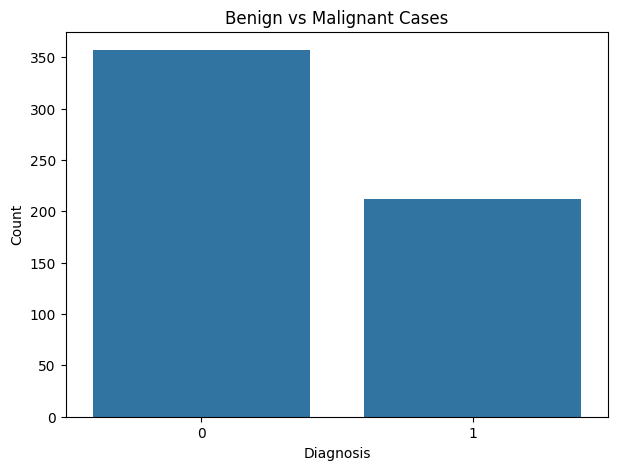

In [19]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="diagnosis")

plt.title("Benign vs Malignant Cases")
plt.xlabel("Diagnosis")
plt.ylabel("Count")

plt.show()

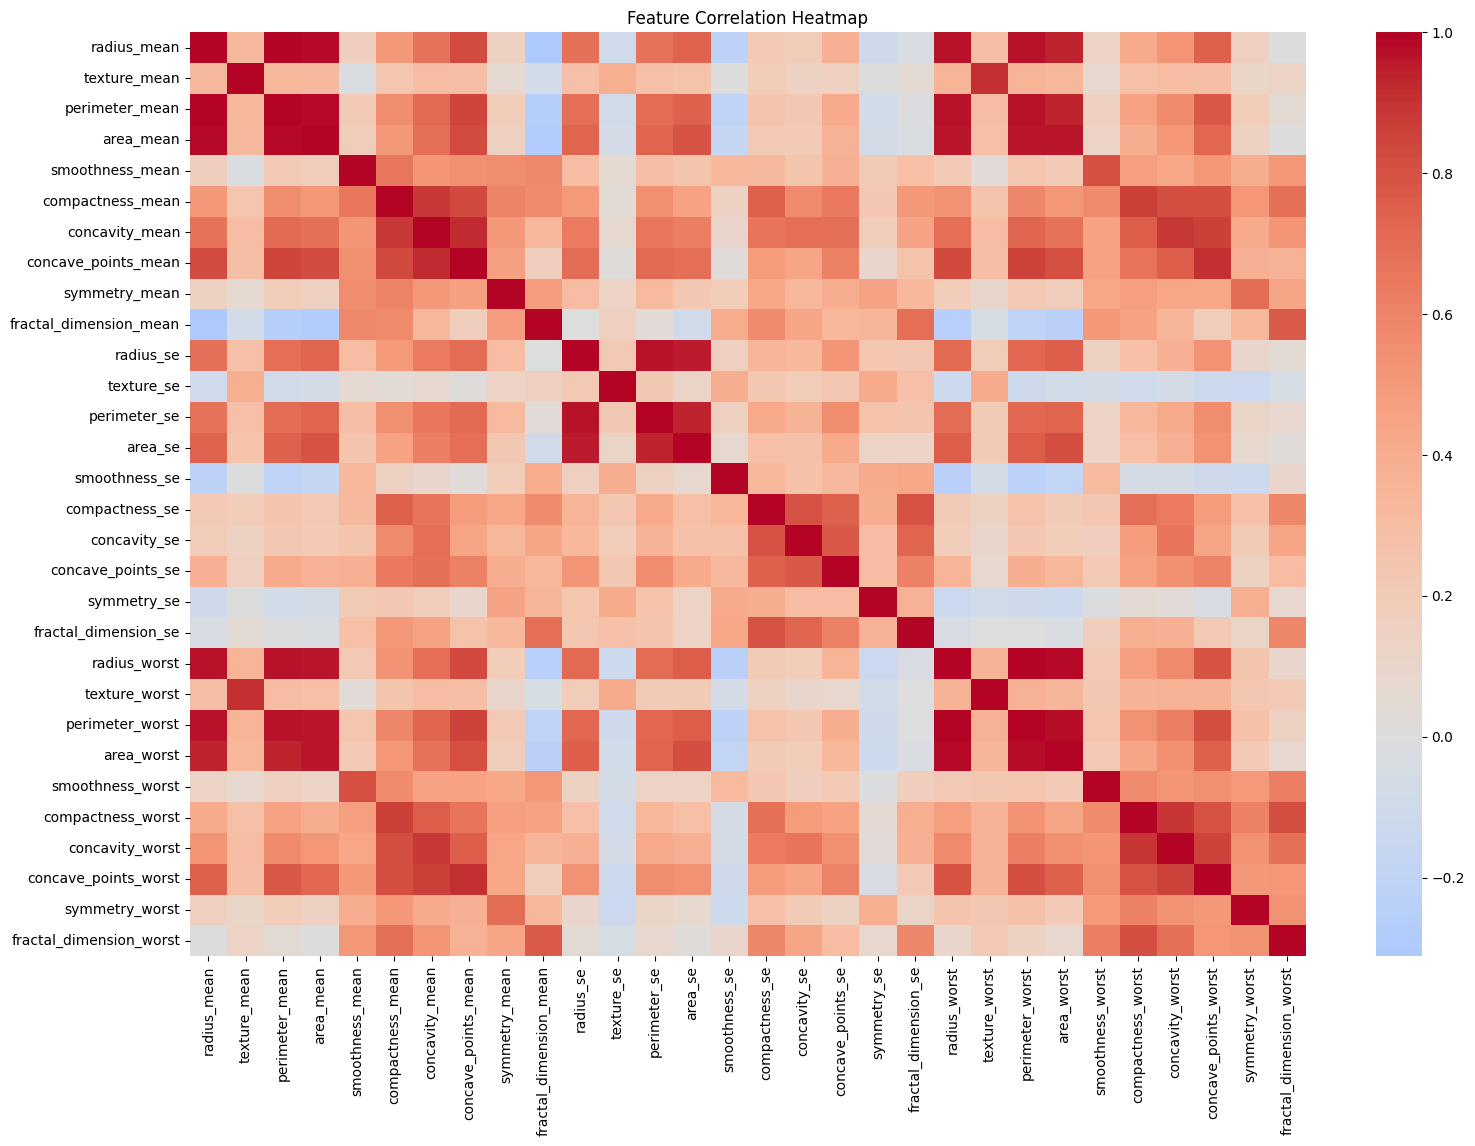

In [20]:
plt.figure(figsize=(18, 12))

correlation_matrix = df[feature_names].corr()

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Heatmap")
plt.show()

## 4. Data Preprocessing

The identifier column is removed because it does not
provide meaningful information for classification.

The diagnosis column is converted into numerical labels:
0 represents Benign and 1 represents Malignant.

In [24]:
# Reload the original dataset

df = pd.read_csv(
    dataset_path,
    header=None,
    names=column_names
)

print("Original dataset restored.")
print("Dataset shape:", df.shape)

df.head()

Original dataset restored.
Dataset shape: (569, 32)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [25]:
# Remove the identifier column

df = df.drop(columns=["id"])

# Convert diagnosis into numerical values

df["diagnosis"] = df["diagnosis"].map({
    "B": 0,
    "M": 1
})

print("Target encoding completed.")

print(df["diagnosis"].value_counts())

print("\nFinal dataset shape:", df.shape)

Target encoding completed.
diagnosis
0    357
1    212
Name: count, dtype: int64

Final dataset shape: (569, 31)


In [26]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (455, 30)
Testing data: (114, 30)


## 5. Model Training and Performance Evaluation

Five classification algorithms are implemented using the
training dataset. Their performance is evaluated using
accuracy, AUC, precision, recall, F1 score and MCC.

In [27]:

# ============================================================
# 1. IMPORT REQUIRED LIBRARIES
# ============================================================

import joblib
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

# ============================================================
# 2. CREATE MODEL DIRECTORY
# ============================================================

model_folder = Path("models")
model_folder.mkdir(exist_ok=True)

# ============================================================
# 3. INITIALIZE FIVE CLASSIFICATION MODELS
# ============================================================

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(
            n_neighbors=5
        ))
    ]),

    "Naive Bayes": GaussianNB(),

    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            probability=True,
            random_state=42
        ))
    ])
}

# ============================================================
# 4. TRAIN MODELS AND CALCULATE EVALUATION METRICS
# ============================================================

results = []

model_filenames = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "k_nearest_neighbors.joblib",
    "Naive Bayes": "gaussian_naive_bayes.joblib",
    "Support Vector Machine": "support_vector_machine.joblib"
}

for model_name, model in models.items():

    print("\n" + "=" * 60)
    print("MODEL:", model_name)
    print("=" * 60)

    # Train the model
    model.fit(X_train, y_train)

    # Generate predictions
    y_pred = model.predict(X_test)

    # Get probability of positive class (Malignant = 1)
    y_probability = model.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    auc = roc_auc_score(y_test, y_probability)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    mcc = matthews_corrcoef(y_test, y_pred)

    # Store the results
    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "MCC": mcc
    })

    # Display confusion matrix
    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

    # Display classification report
    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Benign", "Malignant"],
        zero_division=0
    ))

    # Save trained model
    joblib.dump(
        model,
        model_folder / model_filenames[model_name]
    )

    print("Model saved successfully!")

# ============================================================
# 5. CREATE MODEL COMPARISON TABLE
# ============================================================

results_df = pd.DataFrame(results)

results_df = results_df.set_index("Model")

print("\n\nFINAL MODEL COMPARISON")
print("=" * 90)

display(results_df.round(4))

# ============================================================
# 6. IDENTIFY THE BEST MODEL BASED ON ACCURACY
# ============================================================

best_model_name = results_df["Accuracy"].idxmax()

print("\nBest model based on accuracy:", best_model_name)

# ============================================================
# 7. SAVE EVALUATION RESULTS
# ============================================================

results_df.to_csv("model_metrics.csv")

# ============================================================
# 8. SAVE TEST DATA FOR STREAMLIT APPLICATION
# ============================================================

test_data = X_test.copy()

test_data["diagnosis"] = y_test

test_data.to_csv("test_data.csv", index=False)

print("\n" + "=" * 60)
print("MODEL TRAINING AND EVALUATION COMPLETED")
print("=" * 60)

print("Saved models:", len(models))
print("Saved evaluation results: model_metrics.csv")
print("Saved test dataset: test_data.csv")



MODEL: Logistic Regression

Confusion Matrix:
[[71  1]
 [ 3 39]]

Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114

Model saved successfully!

MODEL: Decision Tree

Confusion Matrix:
[[70  2]
 [ 7 35]]

Classification Report:
              precision    recall  f1-score   support

      Benign       0.91      0.97      0.94        72
   Malignant       0.95      0.83      0.89        42

    accuracy                           0.92       114
   macro avg       0.93      0.90      0.91       114
weighted avg       0.92      0.92      0.92       114

Model saved successfully!

MODEL: KNN

Confusion Matrix:
[[71  1]
 [ 4 38]]

Classification Report:
              precision    recall  f1-score   

,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Model,,,,,,
Logistic Regression,0.9649,0.9960,0.9750,0.9286,0.9512,0.9245
Decision Tree,0.9211,0.9448,0.9459,0.8333,0.8861,0.8299
KNN,0.9561,0.9823,0.9744,0.9048,0.9383,0.9058
Naive Bayes,0.9386,0.9934,1.0000,0.8333,0.9091,0.8715
Support Vector Machine,0.9737,0.9947,1.0000,0.9286,0.9630,0.9442



Best model based on accuracy: Support Vector Machine

MODEL TRAINING AND EVALUATION COMPLETED
Saved models: 5
Saved evaluation results: model_metrics.csv
Saved test dataset: test_data.csv


## 6. Comparison of Classification Models

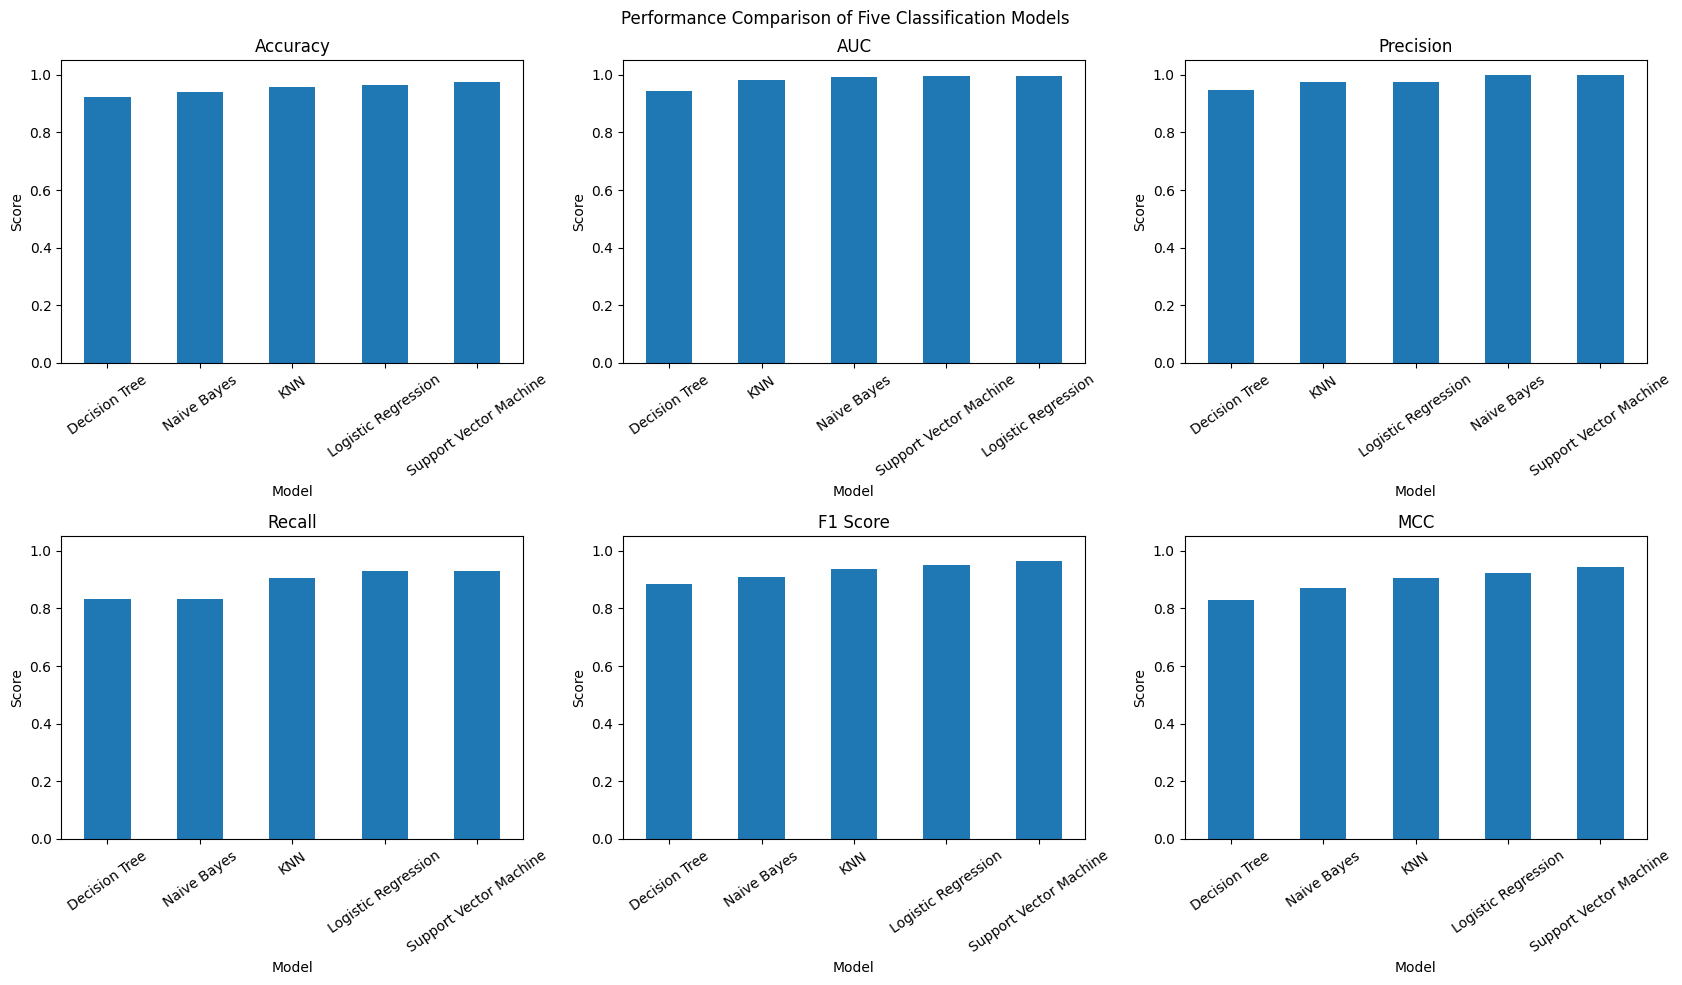

In [28]:

# Compare the performance of all five models

metrics_to_plot = [
    "Accuracy", "AUC", "Precision",
    "Recall", "F1 Score", "MCC"
]

fig, axes = plt.subplots(2, 3, figsize=(17, 10))

for ax, metric in zip(axes.flatten(), metrics_to_plot):

    results_df[metric].sort_values().plot(
        kind="bar",
        ax=ax,
        title=metric
    )

    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Score")
    ax.tick_params(axis="x", rotation=35)

plt.suptitle("Performance Comparison of Five Classification Models")
plt.tight_layout()
plt.show()


In [29]:
print("Project files generated:")

for file in Path(".").iterdir():
    print(file.name)

print("\nSaved models:")

for file in model_folder.glob("*.joblib"):
    print(file.name)

Project files generated:
.gitignore
app.py
assignment2.ipynb
data
models
model_metrics.csv
README.md
requirements.txt
test_data.csv
train.py
venv

Saved models:
decision_tree.joblib
gaussian_naive_bayes.joblib
k_nearest_neighbors.joblib
logistic_regression.joblib
support_vector_machine.joblib
